# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [3]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [4]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


In [7]:
# Recreate the capped dataset
p95 = df['price'].quantile(0.95)

df_cap = df.copy()
df_cap['price_capped'] = df_cap['price'].clip(upper=p95)

## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

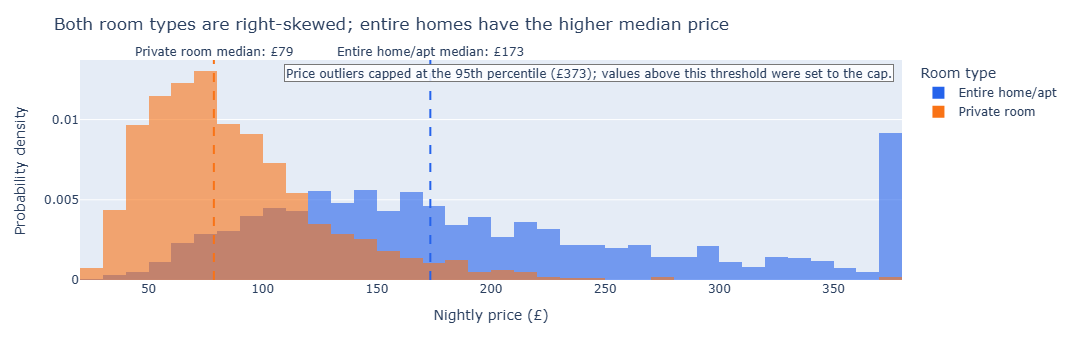

In [8]:
# Task 1
# YOUR CODE HERE
room_order = ['Entire home/apt', 'Private room']
hist_df = df_cap[df_cap['room_type'].isin(room_order)].dropna(subset=['price_capped'])
room_colors = {'Entire home/apt': '#2563EB', 'Private room': '#F97316'}

fig1 = px.histogram(
    hist_df,
    x='price_capped',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    histnorm='probability density',
    nbins=50,
    category_orders={'room_type': room_order},
    color_discrete_map=room_colors,
    labels={'price_capped': 'Nightly price (£, capped at 95th percentile)', 'room_type': 'Room type'},
)

# Median reference line for each room type
for room in room_order:
    median_price = hist_df.loc[hist_df['room_type'] == room, 'price_capped'].median()
    fig1.add_vline(
        x=median_price,
        line_dash='dash',
        line_width=2,
        line_color=room_colors[room],
        annotation_text=f'{room} median: £{median_price:.0f}',
        annotation_position='top',
    )

fig1.update_layout(
    title='Both room types are right-skewed; entire homes have the higher median price',
    xaxis_title='Nightly price (£)',
    yaxis_title='Probability density',
    legend_title='Room type',
)
fig1.add_annotation(
    x=0.99, y=0.98, xref='paper', yref='paper',
    text=f"Price outliers capped at the 95th percentile (£{p95:.0f}); values above this threshold were set to the cap.",
    showarrow=False, xanchor='right', yanchor='top',
    bgcolor='rgba(255,255,255,0.85)', bordercolor='#777', borderwidth=1,
)
fig1.show()

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

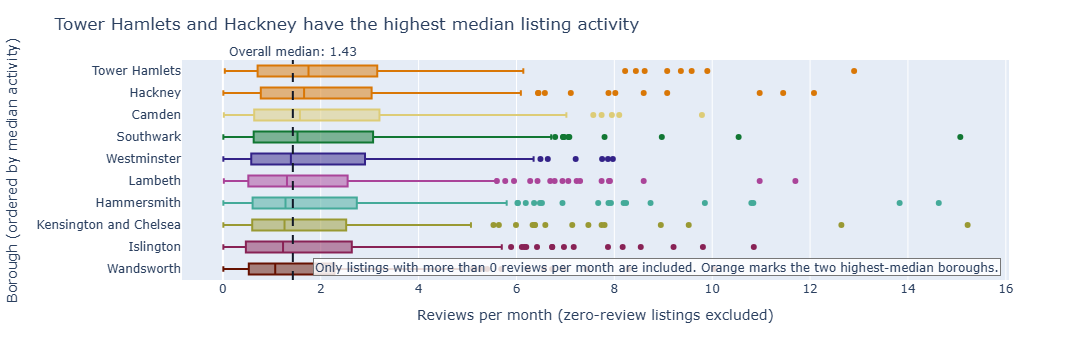

In [9]:
# Task 2
# YOUR CODE HERE
# Use the borough/neighbourhood field available in this dataset.
borough_col = next((c for c in ['neighbourhood_cleansed', 'borough', 'neighbourhood'] if c in df.columns), None)
if borough_col is None:
    raise KeyError("Could not find a borough column. Check the dataset's neighbourhood/borough field name.")

activity = df[[borough_col, 'reviews_per_month']].dropna().copy()
activity = activity[activity['reviews_per_month'] > 0]  # remove zero-review listings
borough_medians = activity.groupby(borough_col)['reviews_per_month'].median().sort_values(ascending=False)
top_two = borough_medians.head(2).index.tolist()
borough_order = borough_medians.index.tolist()

# Give each borough a consistent colour; highlight the two highest-median boroughs.
palette = px.colors.qualitative.Safe
borough_colors = {borough: '#D97706' if borough in top_two else palette[i % len(palette)]
                  for i, borough in enumerate(borough_order)}

fig2 = px.box(
    activity,
    x='reviews_per_month',
    y=borough_col,
    orientation='h',
    color=borough_col,
    color_discrete_map=borough_colors,
    category_orders={borough_col: borough_order},
    points='outliers',
    labels={'reviews_per_month': 'Reviews per month', borough_col: 'Borough'},
)
overall_median = activity['reviews_per_month'].median()
fig2.add_vline(
    x=overall_median, line_dash='dash', line_color='#111827', line_width=2,
    annotation_text=f'Overall median: {overall_median:.2f}',
    annotation_position='top',
)
fig2.update_layout(
    title=f"{top_two[0]} and {top_two[1]} have the highest median listing activity",
    xaxis_title='Reviews per month (zero-review listings excluded)',
    yaxis_title='Borough (ordered by median activity)',
    showlegend=False,
)
fig2.add_annotation(
    x=0.99, y=0.02, xref='paper', yref='paper',
    text='Only listings with more than 0 reviews per month are included. Orange marks the two highest-median boroughs.',
    showarrow=False, xanchor='right', yanchor='bottom',
    bgcolor='rgba(255,255,255,0.85)', bordercolor='#777', borderwidth=1,
)
fig2.show()